In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Load dataset
data = load_iris()

X = data.data
y = data.target

print("Dataset shape:", X.shape)
print("Classes:", data.target_names)

Dataset shape: (150, 4)
Classes: ['setosa' 'versicolor' 'virginica']


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=10,
    stratify=y
)

# Normalize the input features
normalizer = StandardScaler()

X_train = normalizer.fit_transform(X_train)
X_test = normalizer.transform(X_test)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (120, 4)
X_test: (30, 4)


In [12]:
np.random.seed(10)

# Network architecture
input_size = 4
hidden_size = 6
classes = 3

# First layer
weights_hidden = np.random.uniform(
    -0.5, 0.5, (input_size, hidden_size)
)
bias_hidden = np.zeros(hidden_size)

# Output layer
weights_output = np.random.uniform(
    -0.5, 0.5, (hidden_size, classes)
)
bias_output = np.zeros(classes)

print("Hidden layer weights:", weights_hidden.shape)
print("Output layer weights:", weights_output.shape)

Hidden layer weights: (4, 6)
Output layer weights: (6, 3)


In [13]:
def relu(x):
    return np.where(x > 0, x, 0)


def softmax(x):
    x = x - np.max(x, axis=1, keepdims=True)
    probabilities = np.exp(x)
    return probabilities / np.sum(
        probabilities, axis=1, keepdims=True
    )

In [14]:
# Hidden layer calculation
hidden_input = X_test @ weights_hidden + bias_hidden
hidden_output = relu(hidden_input)

# Output layer calculation
final_input = hidden_output @ weights_output + bias_output
final_output = softmax(final_input)

print("Hidden layer output shape:", hidden_output.shape)
print("Final output shape:", final_output.shape)

Hidden layer output shape: (30, 6)
Final output shape: (30, 3)


In [15]:
predicted_class = np.argmax(final_output, axis=1)

predicted_flower = data.target_names[predicted_class]

print("Predicted Classes:")
print(predicted_class)

print("\nPredicted Iris Species:")
print(predicted_flower)

Predicted Classes:
[2 2 2 2 2 2 2 2 1 2 2 2 2 2 2 2 2 2 1 2 2 2 2 2 2 2 2 2 2 2]

Predicted Iris Species:
['virginica' 'virginica' 'virginica' 'virginica' 'virginica' 'virginica'
 'virginica' 'virginica' 'versicolor' 'virginica' 'virginica' 'virginica'
 'virginica' 'virginica' 'virginica' 'virginica' 'virginica' 'virginica'
 'versicolor' 'virginica' 'virginica' 'virginica' 'virginica' 'virginica'
 'virginica' 'virginica' 'virginica' 'virginica' 'virginica' 'virginica']


In [16]:
prediction_table = pd.DataFrame({
    "Actual": data.target_names[y_test],
    "Predicted": predicted_flower,
    "Setosa (%)": final_output[:, 0] * 100,
    "Versicolor (%)": final_output[:, 1] * 100,
    "Virginica (%)": final_output[:, 2] * 100
})

prediction_table = prediction_table.round(2)

display(prediction_table.head(10))

,Actual,Predicted,Setosa (%),Versicolor (%),Virginica (%)
0,versicolor,virginica,34.44,30.15,35.41
1,setosa,virginica,30.63,31.33,38.04
2,versicolor,virginica,32.57,33.08,34.35
3,virginica,virginica,33.81,28.64,37.55
4,versicolor,virginica,34.28,29.41,36.31
5,virginica,virginica,34.27,25.04,40.68
6,setosa,virginica,31.84,32.63,35.52
7,virginica,virginica,33.92,28.62,37.46
8,virginica,versicolor,31.22,34.44,34.34
9,setosa,virginica,27.05,35.43,37.52


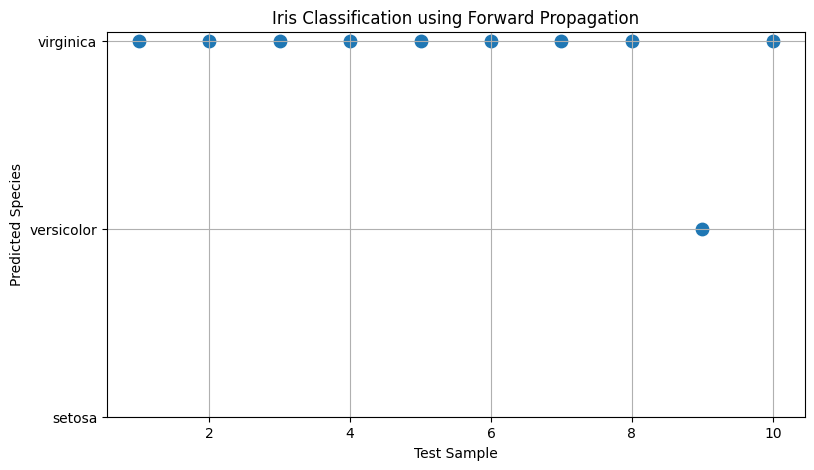

In [17]:
plt.figure(figsize=(9, 5))

plt.scatter(
    range(1, 11),
    predicted_class[:10],
    s=80
)

plt.yticks(
    [0, 1, 2],
    data.target_names
)

plt.xlabel("Test Sample")
plt.ylabel("Predicted Species")
plt.title("Iris Classification using Forward Propagation")
plt.grid()

plt.show()

In [18]:
np.random.randn()

0.4002099882523482